In [ ]:
import rasterio

files = {
    "Blue (B02)": "D:\GISLab\Prog-For-GIS\Lab4\B02.tif",
    "Green (B03)": "D:\GISLab\Prog-For-GIS\Lab4\B03.tif",
    "Red (B04)": "D:\GISLab\Prog-For-GIS\Lab4\B04.tif"
}

for name, file in files.items():

    dataset = rasterio.open(file)

    print("\n", name)
    print("Width:", dataset.width)
    print("Height:", dataset.height)
    print("Bands:", dataset.count)
    print("CRS:", dataset.crs)
    print("Resolution:", dataset.res)

    dataset.close()


 Blue (B02)
Minimum: 1407
Maximum: 3803
Mean: 1687.8061702182088


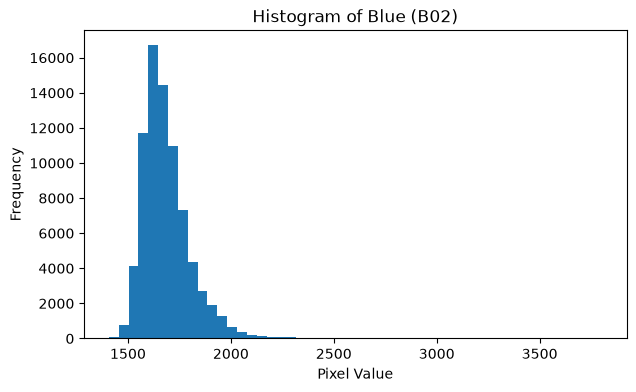


 Green (B03)
Minimum: 1493
Maximum: 3944
Mean: 1806.5523010411603


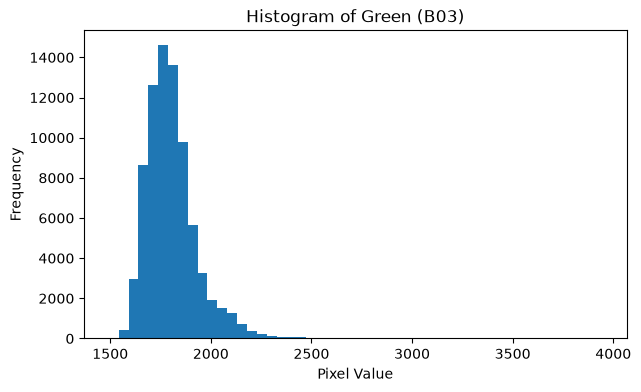


 Red (B04)
Minimum: 1327
Maximum: 3742
Mean: 1717.0200429766442


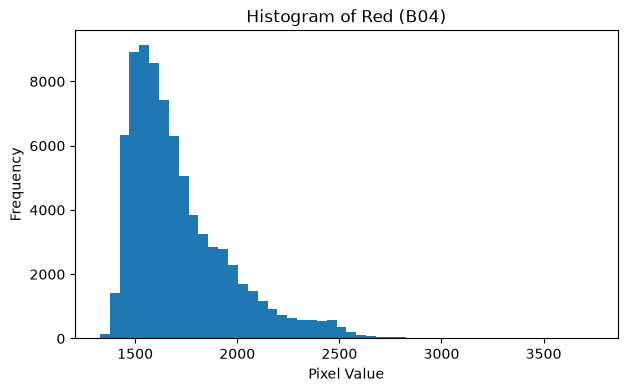

In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

files = {
    "Blue (B02)": "B02.tif",
    "Green (B03)": "B03.tif",
    "Red (B04)": "B04.tif"
}

for name, file in files.items():

    with rasterio.open(file) as dataset:

        band = dataset.read(1)

        print("\n", name)
        print("Minimum:", np.min(band))
        print("Maximum:", np.max(band))
        print("Mean:", np.mean(band))

        plt.figure(figsize=(7, 4))

        plt.hist(band.flatten(), bins=50)

        plt.title("Histogram of " + name)
        plt.xlabel("Pixel Value")
        plt.ylabel("Frequency")

        plt.show()

In [2]:
import rasterio
import numpy as np

files = ["B02.tif", "B03.tif", "B04.tif"]

bands = []

for file in files:

    with rasterio.open(file) as src:

        bands.append(src.read(1))

        profile = src.profile.copy()

# Stack bands
stacked = np.stack(bands, axis=0)

profile.update(
    count=3,
    dtype=stacked.dtype
)

with rasterio.open("stacked_image.tif", "w", **profile) as dst:

    dst.write(stacked)

print("Band stacking completed!")

Band stacking completed!


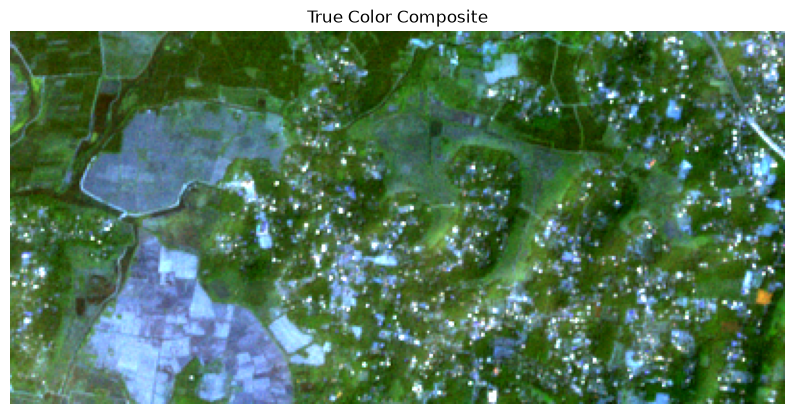

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

with rasterio.open("stacked_image.tif") as src:

    # Read all three bands
    rgb = src.read()

# Rearrange from (bands, rows, columns)
# to (rows, columns, bands)
rgb = np.transpose(rgb, (1, 2, 0))

# Contrast enhancement using percentile stretching
p2 = np.percentile(rgb, 2)
p98 = np.percentile(rgb, 98)

rgb_display = np.clip(
    (rgb - p2) / (p98 - p2),
    0, 1
)

# Display image
plt.figure(figsize=(10, 8))
plt.imshow(rgb_display)

plt.title("True Color Composite")
plt.axis("off")
plt.show()

Bands found: ['_B02.tif', '_B03.tif', '_B04.tif']
Full image shape: (3, 194, 403)
Saved: D:\GISLab\Prog-For-GIS\Lab4\clipped_aoi.tif (3, 100, 150)


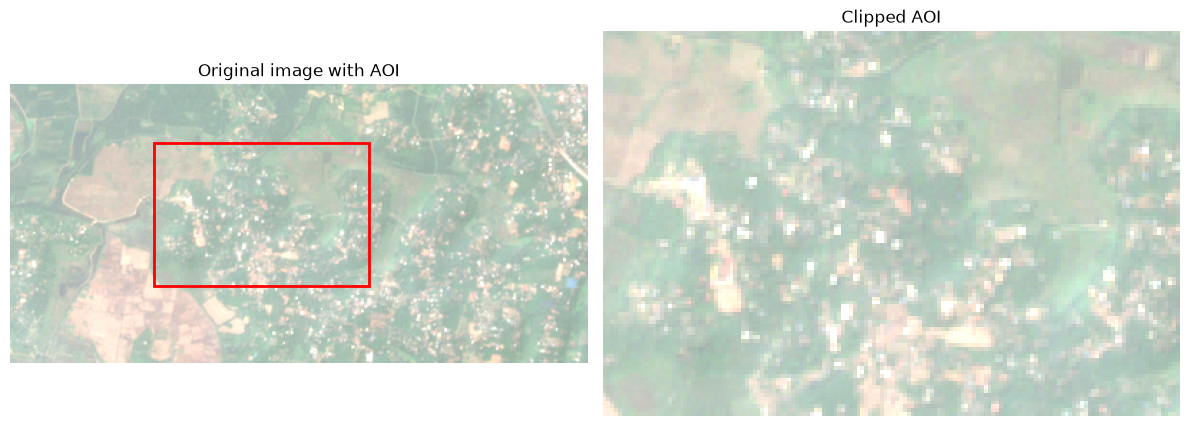

In [2]:
import os, glob
import numpy as np
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

# ---- find the band files (matches B02.tif and _B02.tif) ----
folder = r"D:\GISLab\Prog-For-GIS\Lab4"
band_files = sorted(glob.glob(os.path.join(folder, "*B0[2-4].tif")))
print("Bands found:", [os.path.basename(f) for f in band_files])
assert len(band_files) == 3, "Files not found - check the folder path"

# ---- read bands ----
arrays = []
for f in band_files:
    with rasterio.open(f) as src:
        arrays.append(src.read(1))
        profile = src.profile.copy()
        transform = src.transform
stack = np.stack(arrays)
print("Full image shape:", stack.shape)

# ---- Task 5: clip AOI ----
col_off, row_off = 100, 40
width, height = 150, 100

window = Window(col_off, row_off, width, height)
clip = stack[:, row_off:row_off + height, col_off:col_off + width]
clip_transform = rasterio.windows.transform(window, transform)

profile.update(driver="GTiff", height=clip.shape[1], width=clip.shape[2],
               count=clip.shape[0], transform=clip_transform)

out_path = os.path.join(folder, "clipped_aoi.tif")
with rasterio.open(out_path, "w", **profile) as dst:
    dst.write(clip)
print("Saved:", out_path, clip.shape)

# ---- display ----
def rgb(arr):
    img = np.dstack([arr[2], arr[1], arr[0]]).astype("float32")
    return np.clip(img / np.percentile(img, 98), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(rgb(stack))
ax[0].add_patch(plt.Rectangle((col_off, row_off), width, height,
                              fill=False, edgecolor="red", linewidth=2))
ax[0].set_title("Original image with AOI")
ax[1].imshow(rgb(clip))
ax[1].set_title("Clipped AOI")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

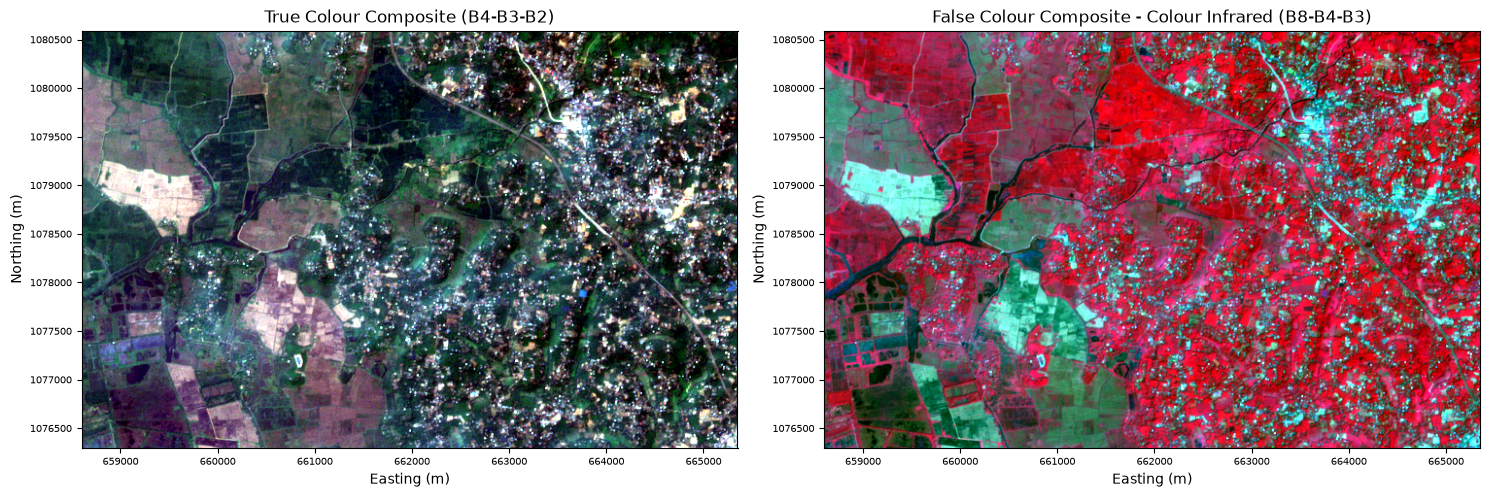

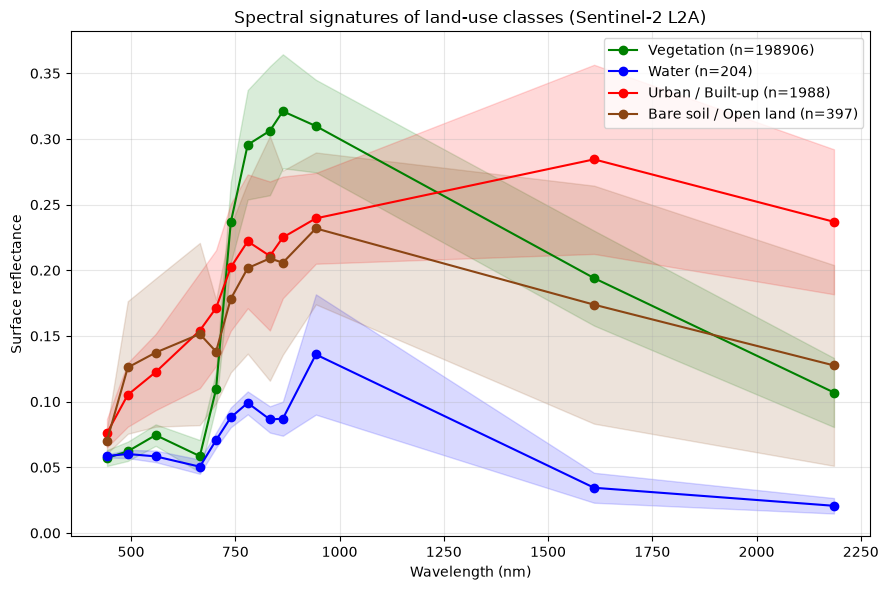


----- Task 7 results -----
NDVI range            : 0.001 to 0.866
NDVI threshold        : > 0.3
Vegetated pixels      : 272950 of 289575
Vegetated area        : 27.295 km2  (2729.5 ha)
Total image area      : 28.957 km2
Vegetation coverage   : 94.3 %


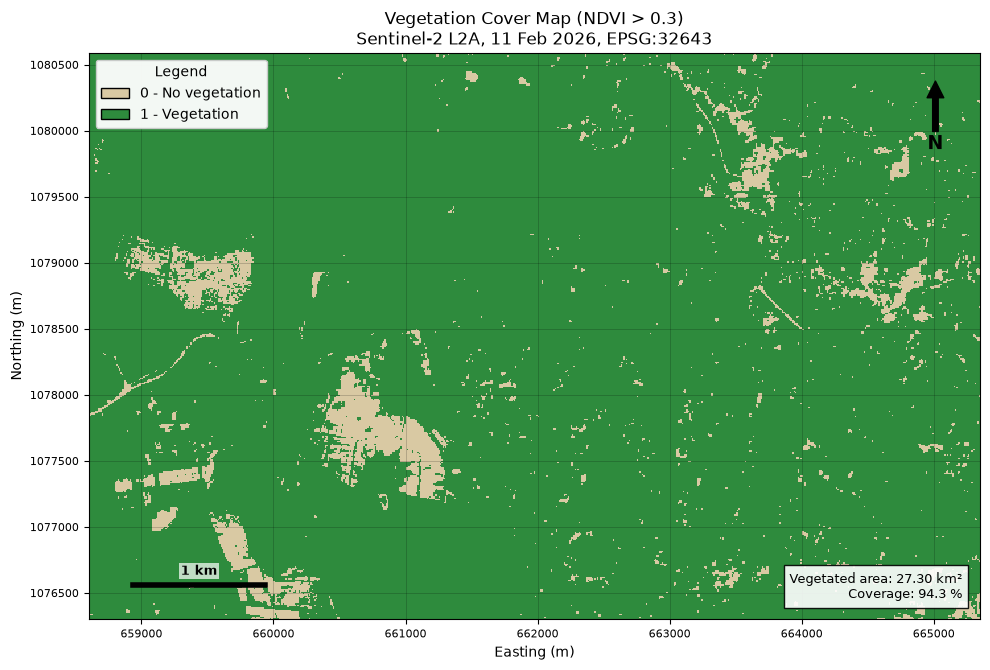

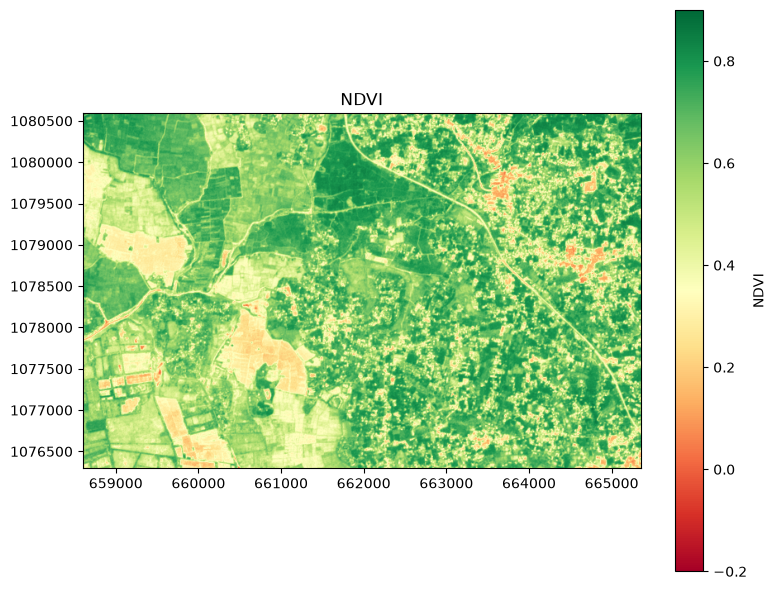

In [3]:
"""
ESG 633 - Lab 4: Satellite Data Processing
Tasks 4 (True/False colour composite), 6 (spectral signatures), 7 (NDVI + vegetation map)
Sentinel-2 L2A, tile T43PFL, 11 Feb 2026
"""
import glob, os, zipfile
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ------------------------------------------------------------------ SETTINGS
ZIP_PATH = "sentinel-2-l2a_2026-02-11_S2B_MSIL2A_20260211T050839_R019_T43PFL_20260211T090300.zip"
WORK_DIR = "s2_data"          # folder where the zip is extracted
OUT_DIR  = "outputs"          # figures are saved here
NDVI_THRESHOLD = 0.3          # NDVI > threshold  ->  vegetation
# Sentinel-2 L2A products processed with baseline >= 04.00 (Jan 2022 onwards)
# carry a +1000 DN offset:  reflectance = (DN - 1000) / 10000
BOA_ADD_OFFSET = 1000
SCALE = 10000.0

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------------------------ LOAD DATA
if not glob.glob(os.path.join(WORK_DIR, "*.tif")):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(WORK_DIR)

def band_path(name):
    return glob.glob(os.path.join(WORK_DIR, f"*_{name}.tif"))[0]

# Reference grid = a 10 m band (B02). Every other band is resampled onto it,
# because Sentinel-2 bands come at 10 m, 20 m and 60 m resolution.
with rasterio.open(band_path("B02")) as ref:
    H, W = ref.shape
    transform, crs, bounds = ref.transform, ref.crs, ref.bounds
    extent = plotting_extent(ref)          # (left, right, bottom, top)
    pixel_area_m2 = abs(ref.res[0] * ref.res[1])

def read_band(name, resampling=Resampling.bilinear, to_reflectance=True):
    """Read a band, resampled to the 10 m grid. Returns float32 reflectance (0-1)."""
    with rasterio.open(band_path(name)) as src:
        arr = src.read(1, out_shape=(H, W), resampling=resampling).astype("float32")
    if to_reflectance:
        arr = np.clip((arr - BOA_ADD_OFFSET) / SCALE, 0, 1)
    return arr

bands = {n: read_band(n) for n in
         ["B01","B02","B03","B04","B05","B06","B07","B08","B8A","B09","B11","B12"]}
scl = read_band("SCL", Resampling.nearest, to_reflectance=False).astype("uint8")

blue, green, red, nir = bands["B02"], bands["B03"], bands["B04"], bands["B08"]


# =========================================================== TASK 4: COMPOSITES
def stretch(a, low=2, high=98):
    """2-98 percentile contrast stretch to 0-1 for display."""
    lo, hi = np.nanpercentile(a, (low, high))
    return np.clip((a - lo) / (hi - lo + 1e-9), 0, 1)

true_color  = np.dstack([stretch(red),  stretch(green), stretch(blue)])   # R,G,B = B04,B03,B02
false_color = np.dstack([stretch(nir),  stretch(red),   stretch(green)])  # R,G,B = B08,B04,B03

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(true_color, extent=extent)
ax[0].set_title("True Colour Composite (B4-B3-B2)")
ax[1].imshow(false_color, extent=extent)
ax[1].set_title("False Colour Composite - Colour Infrared (B8-B4-B3)")
for a in ax:
    a.set_xlabel("Easting (m)"); a.set_ylabel("Northing (m)")
    a.ticklabel_format(style="plain"); a.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "task4_composites.png"), dpi=200)
plt.show()


# ================================================== TASK 6: SPECTRAL SIGNATURES
# Band centre wavelengths (nm) for Sentinel-2B
wavelengths = {"B01":442.2, "B02":492.1, "B03":559.0, "B04":664.9, "B05":703.8,
               "B06":739.1, "B07":779.7, "B08":832.9, "B8A":864.0, "B09":943.2,
               "B11":1610.4, "B12":2185.7}
order = list(wavelengths)                         # ascending wavelength
wl = np.array([wavelengths[b] for b in order])
cube = np.stack([bands[b] for b in order])        # (bands, rows, cols)

ndvi = (nir - red) / (nir + red + 1e-10)
mndwi = (green - bands["B11"]) / (green + bands["B11"] + 1e-10)   # water index
ndbi  = (bands["B11"] - nir) / (bands["B11"] + nir + 1e-10)       # built-up index

# Land-use classes picked with the Scene Classification Layer (SCL) plus indices,
# so no manual pixel picking is needed.  SCL: 4=vegetation, 5=not-vegetated, 6=water
masks = {
    "Vegetation": (scl == 4) & (ndvi > 0.5),
    "Water":      (scl == 6) & (mndwi > 0),
    "Urban / Built-up": (scl == 5) & (ndbi > 0) & (ndvi < 0.2),
    "Bare soil / Open land": (scl == 5) & (ndbi <= 0) & (ndvi < 0.2),
}
colors = {"Vegetation":"green", "Water":"blue", "Urban / Built-up":"red",
          "Bare soil / Open land":"saddlebrown"}

fig, ax = plt.subplots(figsize=(9, 6))
for name, m in masks.items():
    n_pix = int(m.sum())
    if n_pix == 0:
        print(f"[!] No pixels found for '{name}' - relax the thresholds or pick pixels manually.")
        continue
    mean_spec = cube[:, m].mean(axis=1)
    std_spec  = cube[:, m].std(axis=1)
    ax.plot(wl, mean_spec, "-o", color=colors[name], label=f"{name} (n={n_pix})")
    ax.fill_between(wl, mean_spec - std_spec, mean_spec + std_spec,
                    color=colors[name], alpha=0.15)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Surface reflectance")
ax.set_title("Spectral signatures of land-use classes (Sentinel-2 L2A)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "task6_spectral_signatures.png"), dpi=200)
plt.show()

# --- Optional: pick specific pixels by (row, col) instead of class averages ----
# points = {"Vegetation": (100, 200), "Water": (50, 60), "Urban": (300, 400)}
# for name, (r, c) in points.items():
#     plt.plot(wl, cube[:, r, c], "-o", label=name)


# ====================================================== TASK 7: NDVI + VEG. AREA
veg = (ndvi > NDVI_THRESHOLD).astype("uint8")       # 0 = no vegetation, 1 = vegetation

veg_pixels  = int(veg.sum())
veg_area_m2 = veg_pixels * pixel_area_m2
total_area_m2 = veg.size * pixel_area_m2
print("\n----- Task 7 results -----")
print(f"NDVI range            : {ndvi.min():.3f} to {ndvi.max():.3f}")
print(f"NDVI threshold        : > {NDVI_THRESHOLD}")
print(f"Vegetated pixels      : {veg_pixels} of {veg.size}")
print(f"Vegetated area        : {veg_area_m2/1e6:.3f} km2  ({veg_area_m2/1e4:.1f} ha)")
print(f"Total image area      : {total_area_m2/1e6:.3f} km2")
print(f"Vegetation coverage   : {100*veg_area_m2/total_area_m2:.1f} %")

# save the binary raster as a GeoTIFF as well
with rasterio.open(os.path.join(OUT_DIR, "vegetation_mask.tif"), "w", driver="GTiff",
                   height=H, width=W, count=1, dtype="uint8",
                   crs=crs, transform=transform) as dst:
    dst.write(veg, 1)

# --- map layout ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))
cmap = ListedColormap(["#d9c9a3", "#2e8b3d"])
ax.imshow(veg, cmap=cmap, vmin=0, vmax=1, extent=extent, interpolation="nearest")
ax.set_title(f"Vegetation Cover Map (NDVI > {NDVI_THRESHOLD})\n"
             f"Sentinel-2 L2A, 11 Feb 2026, {crs.to_string()}", fontsize=12)
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=8)
ax.grid(color="k", alpha=0.25, linewidth=0.5)

# legend
ax.legend(handles=[Patch(facecolor="#d9c9a3", edgecolor="k", label="0 - No vegetation"),
                   Patch(facecolor="#2e8b3d", edgecolor="k", label="1 - Vegetation")],
          loc="upper left", framealpha=0.95, title="Legend")

# north arrow
ax.annotate("N", xy=(0.95, 0.95), xytext=(0.95, 0.83), xycoords="axes fraction",
            ha="center", fontsize=14, fontweight="bold",
            arrowprops=dict(facecolor="k", width=4, headwidth=12))

# scale bar (1 km)
x0 = extent[0] + 0.05 * (extent[1] - extent[0])
y0 = extent[2] + 0.06 * (extent[3] - extent[2])
ax.plot([x0, x0 + 1000], [y0, y0], "k-", linewidth=4)
ax.text(x0 + 500, y0 + 80, "1 km", ha="center", fontsize=9, fontweight="bold",
        bbox=dict(facecolor="white", alpha=0.7, pad=1, edgecolor="none"))

# area text box
ax.text(0.98, 0.03, f"Vegetated area: {veg_area_m2/1e6:.2f} km²\n"
                    f"Coverage: {100*veg_area_m2/total_area_m2:.1f} %",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="k"))

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "task7_vegetation_map.png"), dpi=200)
plt.show()

# NDVI map (extra, useful for the report)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9, extent=extent)
plt.colorbar(im, ax=ax, label="NDVI")
ax.set_title("NDVI"); ax.ticklabel_format(style="plain")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "task7_ndvi.png"), dpi=200)
plt.show()